In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = sns.load_dataset("penguins")
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [6]:
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [7]:
df = df.dropna()

In [8]:
df['species'].nunique()

3

<Axes: >

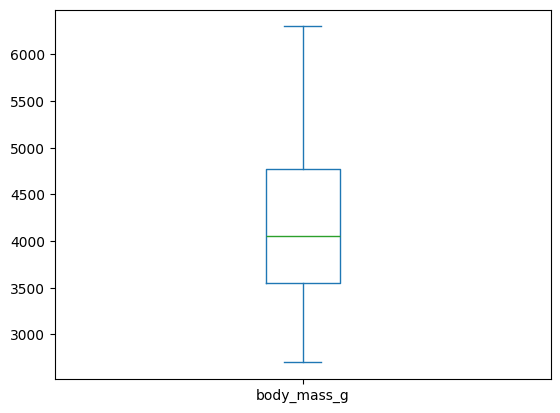

In [9]:
df['body_mass_g'].plot(kind='box')

In [10]:
df['island'].nunique()

3

<Axes: xlabel='sex', ylabel='Count'>

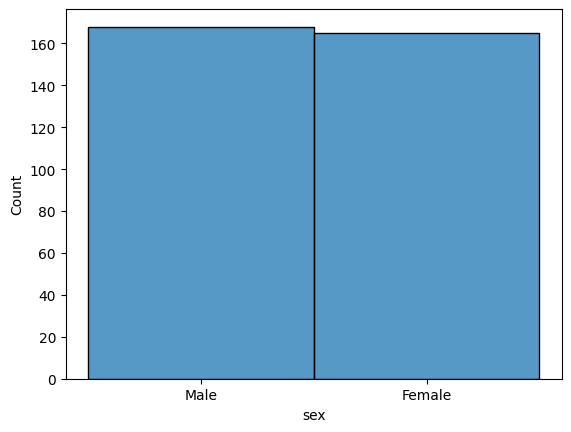

In [11]:
sns.histplot(x='sex', data=df)

<Axes: xlabel='species', ylabel='Count'>

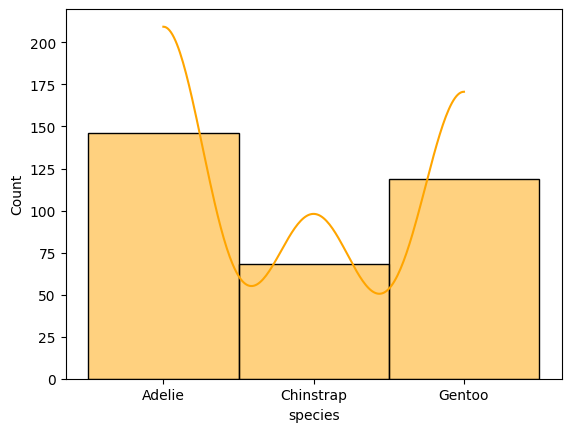

In [12]:
sns.histplot(x='species', data=df, kde=True, color='orange')

In [13]:
df_encoded = pd.get_dummies(df[["species", "island"]]).astype(int)
df_encoded

,species_Adelie,species_Chinstrap,species_Gentoo,island_Biscoe,island_Dream,island_Torgersen
0,1,0,0,0,0,1
1,1,0,0,0,0,1
2,1,0,0,0,0,1
4,1,0,0,0,0,1
5,1,0,0,0,0,1
...,...,...,...,...,...,...
338,0,0,1,1,0,0
340,0,0,1,1,0,0
341,0,0,1,1,0,0
342,0,0,1,1,0,0


In [14]:
df = pd.concat([df.drop(["species", "island"], axis=1), df_encoded], axis=1).reset_index(drop=True)
df

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species_Adelie,species_Chinstrap,species_Gentoo,island_Biscoe,island_Dream,island_Torgersen
0,39.1,18.7,181.0,3750.0,Male,1,0,0,0,0,1
1,39.5,17.4,186.0,3800.0,Female,1,0,0,0,0,1
2,40.3,18.0,195.0,3250.0,Female,1,0,0,0,0,1
3,36.7,19.3,193.0,3450.0,Female,1,0,0,0,0,1
4,39.3,20.6,190.0,3650.0,Male,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
328,47.2,13.7,214.0,4925.0,Female,0,0,1,1,0,0
329,46.8,14.3,215.0,4850.0,Female,0,0,1,1,0,0
330,50.4,15.7,222.0,5750.0,Male,0,0,1,1,0,0
331,45.2,14.8,212.0,5200.0,Female,0,0,1,1,0,0


<Axes: xlabel='sex', ylabel='Count'>

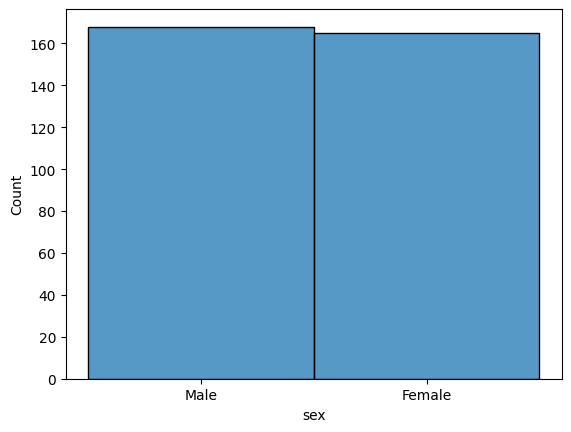

In [15]:
sns.histplot(x='sex', data=df)

In [16]:
df['sex'] = df['sex'].map(lambda x: 1 if x == 'Male' else 0)
df['sex']

0      1
1      0
2      0
3      0
4      1
      ..
328    0
329    0
330    1
331    0
332    1
Name: sex, Length: 333, dtype: int64

In [17]:
X = df.drop('sex', axis=1)
y = df['sex']
print(X.shape, y.shape)

(333, 10) (333,)


## Deal with outliers


### bill_length_mm column outliers


<Axes: xlabel='bill_length_mm'>

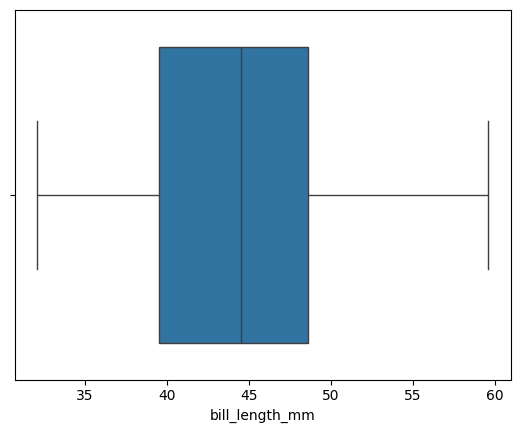

In [18]:
sns.boxplot(x="bill_length_mm" ,data=X)

In [19]:
# cut = X["bill_length_mm"].quantile(0.9)
# X["bill_length_mm"] = X["bill_length_mm"].clip(upper=cut)

### bill_length_mm column outliers


<Axes: xlabel='bill_depth_mm'>

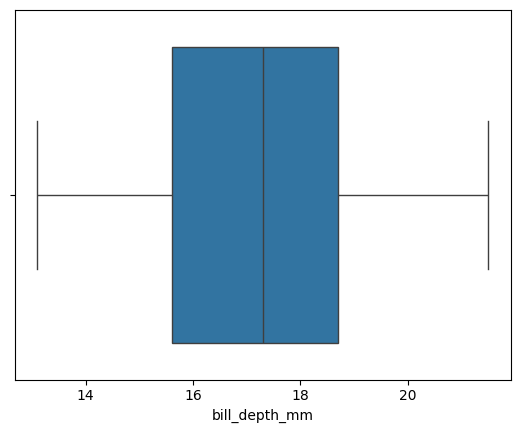

In [20]:
sns.boxplot(x="bill_depth_mm", data=X)

### flipper_length_mm outliers


<Axes: xlabel='flipper_length_mm'>

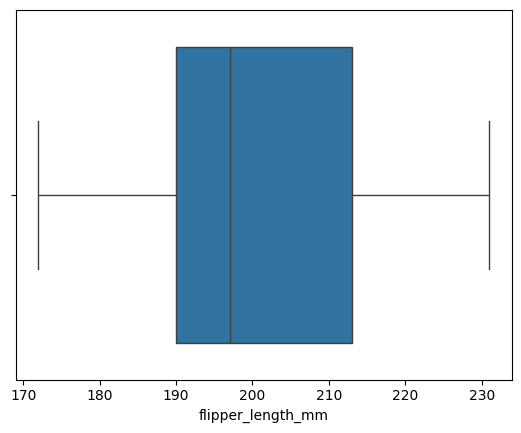

In [21]:
sns.boxplot(x="flipper_length_mm", data=X)

In [22]:
X['flipper_length_mm'].quantile(0.99)

np.float64(230.0)

## Scale


In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X[["bill_length_mm", "flipper_length_mm", "bill_depth_mm", "body_mass_g"]] = scaler.fit_transform(X[["bill_length_mm", "flipper_length_mm", "bill_depth_mm", "body_mass_g"]])
X

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species_Adelie,species_Chinstrap,species_Gentoo,island_Biscoe,island_Dream,island_Torgersen
0,-0.896042,0.780732,-1.426752,-0.568475,1,0,0,0,0,1
1,-0.822788,0.119584,-1.069474,-0.506286,1,0,0,0,0,1
2,-0.676280,0.424729,-0.426373,-1.190361,1,0,0,0,0,1
3,-1.335566,1.085877,-0.569284,-0.941606,1,0,0,0,0,1
4,-0.859415,1.747026,-0.783651,-0.692852,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...
328,0.587352,-1.762145,0.931283,0.892957,0,0,1,1,0,0
329,0.514098,-1.457000,1.002739,0.799674,0,0,1,1,0,0
330,1.173384,-0.744994,1.502928,1.919069,0,0,1,1,0,0
331,0.221082,-1.202712,0.788372,1.234995,0,0,1,1,0,0


In [24]:
X.shape

(333, 10)

## Split into trai_test


In [25]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, y_train.shape) 

(266, 10) (266,)


## Build base model


In [26]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [27]:
y_pred = lr.predict(X_test)

In [28]:
from sklearn.metrics import classification_report, f1_score, accuracy_score, precision_score

In [29]:
from sklearn.metrics import classification_report, f1_score, accuracy_score, precision_score
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.89      0.92      0.90        36
           1       0.90      0.87      0.89        31

    accuracy                           0.90        67
   macro avg       0.90      0.89      0.89        67
weighted avg       0.90      0.90      0.90        67



In [30]:
f1_score(y_pred, y_test)

0.8852459016393442

In [31]:
accuracy_score(y_pred, y_test)

0.8955223880597015

In [32]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(lr, X, y, cv=5, scoring="accuracy")

In [33]:
scores.mean()

np.float64(0.9039348710990502)

### RandomForestClassifier


In [34]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [35]:
y_pred = rf.predict(X_test)

In [36]:
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.86      0.89      0.88        36
           1       0.87      0.84      0.85        31

    accuracy                           0.87        67
   macro avg       0.87      0.86      0.86        67
weighted avg       0.87      0.87      0.87        67



### XGBClassifier


In [37]:
from xgboost import XGBClassifier
xgb = XGBClassifier()
xgb.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [38]:
y_pred = xgb.predict(X_test)

In [39]:
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.89      0.92      0.90        36
           1       0.90      0.87      0.89        31

    accuracy                           0.90        67
   macro avg       0.90      0.89      0.89        67
weighted avg       0.90      0.90      0.90        67



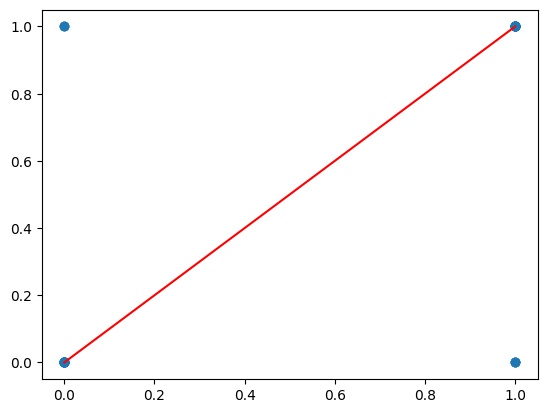

In [51]:
plt.figure()
plt.scatter(y_pred, y_test)
xs = np.linspace(min(y_pred.min(), y_test.min()), max(y_pred.max(), y_test.max()),100)
plt.plot(xs, xs, color='red')

In [47]:
xs = np.linspace(min(y_pred.min(), y_test.min()), max(y_pred.max(), y_test.max()),100)


In [48]:
xs

array([0.        , 0.01010101, 0.02020202, 0.03030303, 0.04040404,
       0.05050505, 0.06060606, 0.07070707, 0.08080808, 0.09090909,
       0.1010101 , 0.11111111, 0.12121212, 0.13131313, 0.14141414,
       0.15151515, 0.16161616, 0.17171717, 0.18181818, 0.19191919,
       0.2020202 , 0.21212121, 0.22222222, 0.23232323, 0.24242424,
       0.25252525, 0.26262626, 0.27272727, 0.28282828, 0.29292929,
       0.3030303 , 0.31313131, 0.32323232, 0.33333333, 0.34343434,
       0.35353535, 0.36363636, 0.37373737, 0.38383838, 0.39393939,
       0.4040404 , 0.41414141, 0.42424242, 0.43434343, 0.44444444,
       0.45454545, 0.46464646, 0.47474747, 0.48484848, 0.49494949,
       0.50505051, 0.51515152, 0.52525253, 0.53535354, 0.54545455,
       0.55555556, 0.56565657, 0.57575758, 0.58585859, 0.5959596 ,
       0.60606061, 0.61616162, 0.62626263, 0.63636364, 0.64646465,
       0.65656566, 0.66666667, 0.67676768, 0.68686869, 0.6969697 ,
       0.70707071, 0.71717172, 0.72727273, 0.73737374, 0.74747

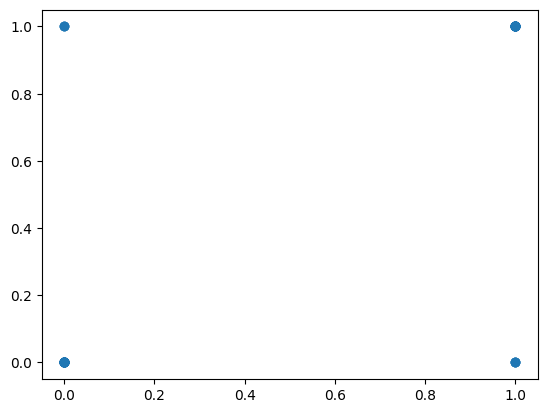

In [50]:
plt.scatter(y_pred, y_test)

(-0.5, 1.5)

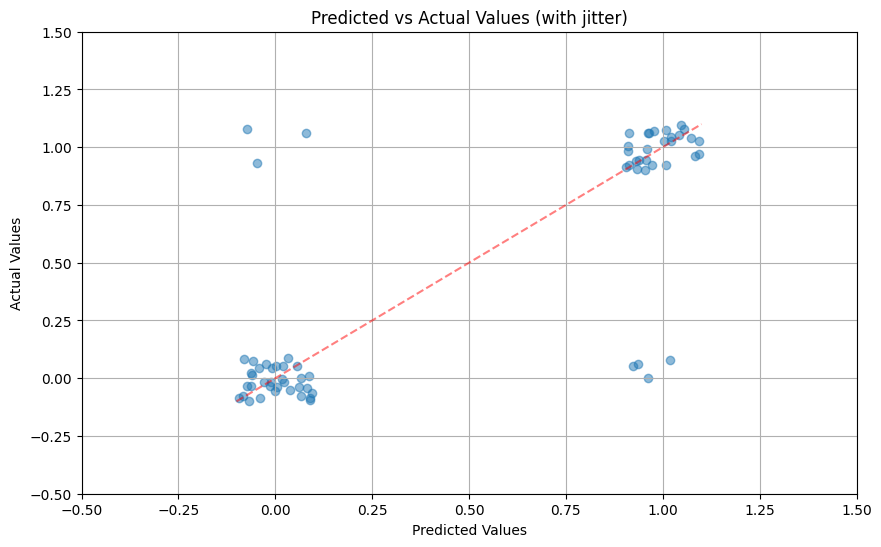

In [52]:
# Add jitter to spread out the points
np.random.seed(42)
jitter_amount = 0.1
y_pred_jitter = y_pred + np.random.uniform(-jitter_amount, jitter_amount, len(y_pred))
y_test_jitter = y_test + np.random.uniform(-jitter_amount, jitter_amount, len(y_test))

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_jitter, y_test_jitter, alpha=0.5)
plt.grid(True)
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Predicted vs Actual Values (with jitter)')

# Add a reference line
plt.plot([0-jitter_amount, 1+jitter_amount], [0-jitter_amount, 1+jitter_amount], 'r--', alpha=0.5)

# Set proper axis limits
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)

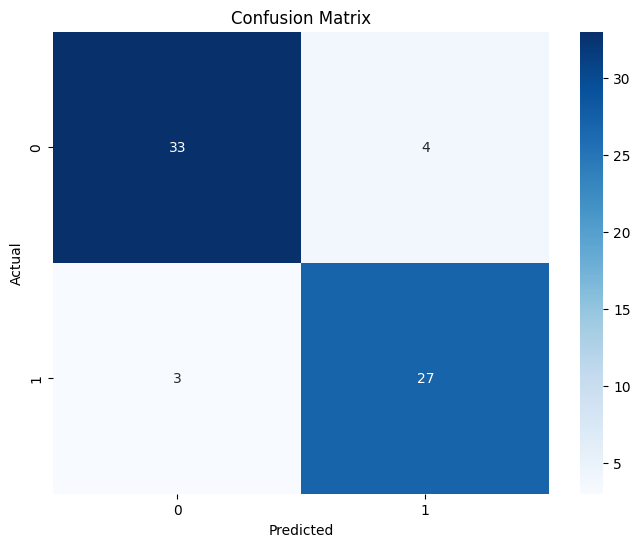

In [53]:
# Create a confusion matrix visualization
from sklearn.metrics import confusion_matrix
import seaborn as sns

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()